# The Perceptron: Foundation of Modern Neural Networks

## Background and History

The **perceptron** is one of the oldest and simplest types of artificial neural networks, invented by Frank Rosenblatt in 1957 at the Cornell Aeronautical Laboratory. It was inspired by biological neurons and represented a major milestone in the development of artificial intelligence.

### What is a Perceptron?

A perceptron is a binary classifier that makes decisions by computing a weighted sum of inputs:

$$f(x) = \begin{cases} 1 & \text{if } w \cdot x + b > 0 \\ 0 & \text{otherwise} \end{cases}$$

Where:
- $x$ is the input vector
- $w$ is the weight vector
- $b$ is the bias term
- $w \cdot x$ is the dot product

### The Perceptron Learning Algorithm

The perceptron learns by adjusting its weights based on errors:

1. Initialize weights randomly
2. For each training example:
   - Compute the predicted output
   - Update weights: $w = w + \eta(y_{true} - y_{pred})x$
   - Update bias: $b = b + \eta(y_{true} - y_{pred})$

Where $\eta$ is the learning rate.

### Historical Significance

The perceptron had a dramatic rise and fall:

- **1958-1969**: Great excitement about perceptrons' potential
- **1969**: Marvin Minsky and Seymour Papert published "Perceptrons," showing that single-layer perceptrons cannot solve XOR and other non-linearly separable problems
- **1969-1986**: The "AI Winter" - reduced funding and interest in neural networks
- **1986+**: Revival with multi-layer perceptrons (MLPs) and backpropagation

## Relevance to Modern Neural Networks

Despite its simplicity, the perceptron is fundamental to understanding modern deep learning:

### 1. **Building Block of Deep Networks**
Modern neural networks are essentially multi-layer perceptrons with:
- Multiple layers stacked together
    - Remember when we were learning about logistic regression, we mentioned that neural nets are like multiple logistic regression stacked together?
    - > Yes
- Non-linear activation functions (ReLU, sigmoid, tanh)
- More sophisticated optimization algorithms (Adam, RMSprop)

### 2. **Core Concepts Remain**
- **Weighted sums**: Still the fundamental operation in every neuron
- **Learning from errors**: Error-driven weight updates are still central
    - > $y_{true} - y_{pred}$
- **Linear decision boundaries**: Understanding why single perceptrons fail helps us understand why non-linearity matters

### 3. **Theoretical Foundation**
- The perceptron convergence theorem guarantees convergence for linearly separable data
- This theoretical framework extends to understanding modern networks
- The limitations (XOR problem) motivated multi-layer architectures

### 4. **Modern Applications**
- **Logistic Regression**: A perceptron with sigmoid activation
- **Support Vector Machines**: Related to finding optimal perceptron boundaries
- **Single neurons in deep networks**: Each neuron in a deep network operates like a perceptron

### From Perceptron to Deep Learning

```
Perceptron (1957)
    ↓
Multi-Layer Perceptron + Backpropagation (1986)
    ↓
Deep Neural Networks (2006+)
    ↓
Modern Architectures: CNNs, RNNs, Transformers (2010s+)
```

---

## Hands-On Exercises

Let's implement and experiment with perceptrons.

### Ex 1. Implement a Perceptron from Scratch

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

class Perceptron:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        """
        Initialize the Perceptron.
        
        Parameters:
        -----------
        learning_rate : float
            Learning rate for weight updates
        n_iterations : int
            Number of training iterations
        """
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.errors = []  # Track errors during training
    
    def fit(self, X, y):
        """
        Train the perceptron.
        
        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            Training data
        y : array-like, shape (n_samples,)
            Target values (0 or 1)
        """
        n_samples, n_features = X.shape
        
        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        # Training loop
        for iteration in range(self.n_iterations):
            errors = 0
            
            for idx, x_i in enumerate(X):
                # Compute prediction
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = self._activation(linear_output)
                
                # Update weights if prediction is wrong
                update = self.learning_rate * (y[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update
                
                # Track errors
                errors += int(update != 0.0)
            
            self.errors.append(errors)
            
            # Early stopping if no errors
            if errors == 0:
                print(f"Converged after {iteration + 1} iterations!")
                break
    
    def predict(self, X):
        """
        Make predictions.
        
        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            Data to predict
        
        Returns:
        --------
        predictions : array, shape (n_samples,)
            Predicted class labels (0 or 1)
        """
        linear_output = np.dot(X, self.weights) + self.bias
        return self._activation(linear_output)
    
    def _activation(self, x):
        """Step activation function."""
        return np.where(x >= 0, 1, 0)

Perceptron class implemented successfully.


In [9]:
# Test the implementation
perceptron_model = Perceptron()
perceptron_model

In [12]:
if isinstance(perceptron_model, Perceptron):
    print("Perceptron class implemented successfully.")
else:
    print("Perceptron class NOT implemented successfully.")

Perceptron class implemented successfully.


### Ex 2. Training a Perceptron on Linearly Separable Data

**Note on `make_classification`**
- `n_samples`: The total number of samples.
- `n_features`: The total number of features.
- `n_informative`: The number of informative features (features that contribute to class separation).
- `n_redundant`: The number of redundant features (linear combinations of informative features).
- `n_repeated`: The number of repeated features (randomly chosen informative and redundant features).
- `n_classes`: The number of classes.
    - > Not same as features?
- `n_clusters_per_class`: The number of clusters per class.
- `weights`: A list of class proportions (for imbalanced datasets).
    - > A method to emphasize the number of samples for the smaller class
- `flip_y`: The fraction of samples whose class labels are randomly flipped.
- `class_sep`: The separation between classes; conceptually the distance between clusters of separate classes.
- `random_state`: For reproducible output.

Converged after 3 iterations!

Test Accuracy: 100.00%


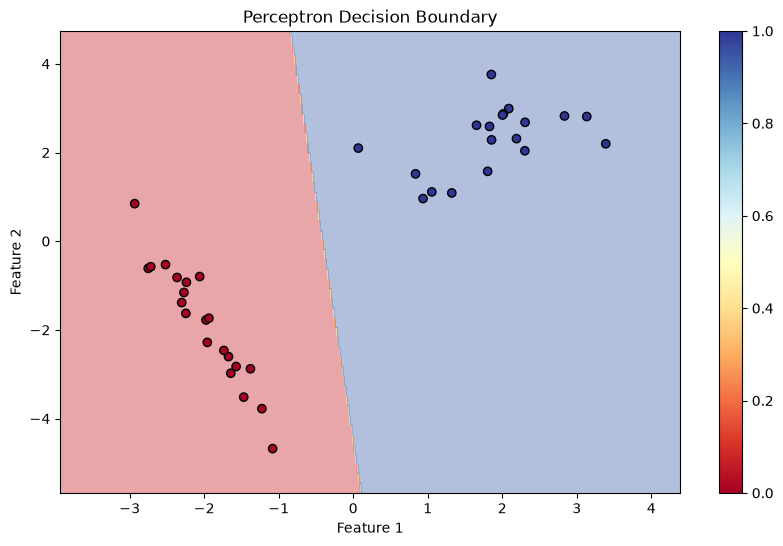

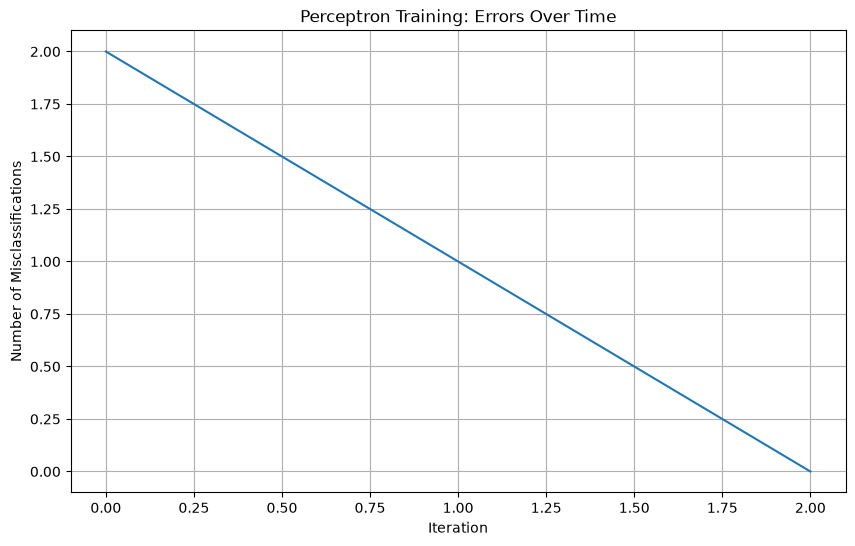

In [ ]:
# Generate linearly separable data
X, y = make_classification(
    n_samples=200,
    n_features=2, # binary classification
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    flip_y=0,
    random_state=6,
    class_sep=2.0
)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the perceptron
perceptron = Perceptron(learning_rate=0.01, n_iterations=1000)
perceptron.fit(X_train, y_train) # > model learning

# Make predictions
y_pred = perceptron.predict(X_test) # > model evaluation

# Calculate accuracy
accuracy = np.mean(y_pred == y_test)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

# Visualize the decision boundary
def plot_decision_boundary(X, y, model, title):
    # Plotting decision boundary based on the two features
    # Set min and max values with some padding
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    # Create a mesh, i.e., a grid of coordinates
    # If xx is [[1, 2], [3, 4]] and yy is [[5, 6], [7, 8]], then: 
    # xx.ravel() would be [1, 2, 3, 4]. --> creating a flattened version of the array
    # yy.ravel() would be [5, 6, 7, 8]

    # np.c_[]: This is a shorthand for numpy.column_stack() and concatenates input arrays along the second axis (columns). 
    # It takes the two 1D arrays and stacks them as columns to create a new array with two columns. 
    # So, np.c_[xx.ravel(), yy.ravel()] would produce the final 2D array: [[1, 5], [2, 6], [3, 7], [4, 8]]
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    # Predict on mesh
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.4, cmap='RdYlBu')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdYlBu', edgecolors='black')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(title)
    plt.colorbar()
    plt.show()

plot_decision_boundary(X_test, y_test, perceptron, 'Perceptron Decision Boundary')

# Plot training errors
plt.figure(figsize=(10, 6))
plt.plot(range(len(perceptron.errors)), perceptron.errors)
plt.xlabel('Iteration')
plt.ylabel('Number of Misclassifications')
plt.title('Perceptron Training: Errors Over Time')
plt.grid(True)
plt.show()

> As we increase in iterations, the number of missclassifications drops

### Ex 3. The XOR Problem - Where Perceptrons Fail

In [3]:
# Create XOR dataset
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])  # XOR output

print("XOR Truth Table:")
print("Input | Output")
print("------|-------")
for i in range(len(X_xor)):
    print(f"{X_xor[i]} | {y_xor[i]}")

XOR Truth Table:
Input | Output
------|-------
[0 0] | 0
[0 1] | 1
[1 0] | 1
[1 1] | 0


- > Ouput 0 and 1 because
    - > 0: same number in input
    - > 1: different numbers in input


Perceptron Predictions on XOR:
Input | True | Predicted
------|------|----------
[0 0] | 0    | 1
[0 1] | 1    | 1
[1 0] | 1    | 0
[1 1] | 0    | 0


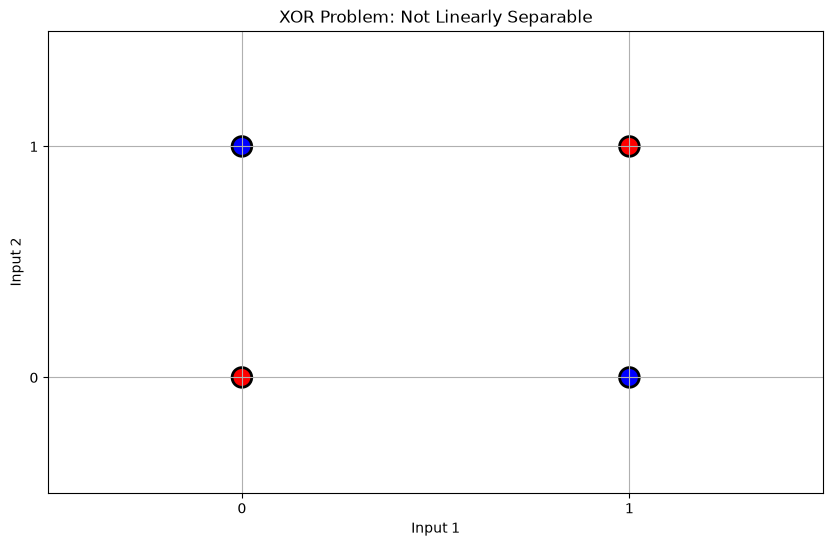


The perceptron cannot solve XOR because it's not linearly separable!
This limitation led to the development of multi-layer neural networks.


In [4]:
# Try to train perceptron on XOR
perceptron_xor = Perceptron(learning_rate=0.1, n_iterations=100)
perceptron_xor.fit(X_xor, y_xor)

# Make predictions
y_pred_xor = perceptron_xor.predict(X_xor)

print("\nPerceptron Predictions on XOR:")
print("Input | True | Predicted")
print("------|------|----------")
for i in range(len(X_xor)):
    print(f"{X_xor[i]} | {y_xor[i]}    | {y_pred_xor[i]}")

# Visualize why it fails
plt.figure(figsize=(10, 6))
colors = ['red' if label == 0 else 'blue' for label in y_xor]
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=colors, s=200, edgecolors='black', linewidths=2)
plt.xlabel('Input 1')
plt.ylabel('Input 2')
plt.title('XOR Problem: Not Linearly Separable')
plt.grid(True)
plt.xticks([0, 1])
plt.yticks([0, 1])

# Try to draw a decision boundary (it won't separate XOR correctly)
if perceptron_xor.weights is not None:
    w = perceptron_xor.weights
    b = perceptron_xor.bias
    x_line = np.linspace(-0.5, 1.5, 100)
    if w[1] != 0:
        y_line = -(w[0] * x_line + b) / w[1]
        plt.plot(x_line, y_line, 'k--', linewidth=2, label='Decision Boundary')
        plt.legend()

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.show()

print("\nThe perceptron cannot solve XOR because it's not linearly separable!")
print("This limitation led to the development of multi-layer neural networks.")

### Ex 4: Solving XOR with a Multi-Layer Perceptron

> `activation='relu'`, max(0, x)

Multi-Layer Perceptron Predictions on XOR:
Input | True | Predicted
------|------|----------
[0 0] | 0    | 0
[0 1] | 1    | 1
[1 0] | 1    | 1
[1 1] | 0    | 0

✅ MLP Accuracy on XOR: 100.00%


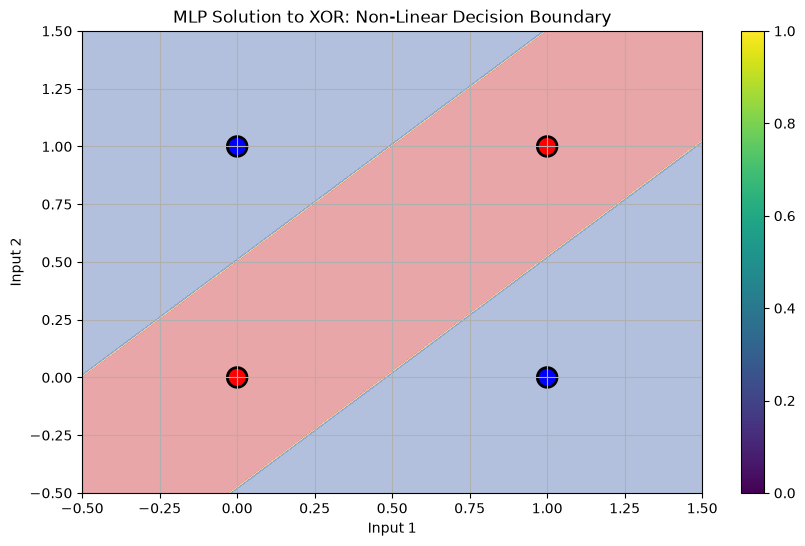


✨ The multi-layer perceptron successfully learns the non-linear XOR function!


In [ ]:
from sklearn.neural_network import MLPClassifier

# Create a simple multi-layer perceptron
mlp = MLPClassifier(
    hidden_layer_sizes=(4,),  # One hidden layer with 4 neurons
    activation='relu',
    max_iter=10000,
    random_state=1
)

# Train on XOR
mlp.fit(X_xor, y_xor)

# Make predictions
y_pred_mlp = mlp.predict(X_xor)

print("Multi-Layer Perceptron Predictions on XOR:")
print("Input | True | Predicted")
print("------|------|----------")
for i in range(len(X_xor)):
    print(f"{X_xor[i]} | {y_xor[i]}    | {y_pred_mlp[i]}")

accuracy_mlp = np.mean(y_pred_mlp == y_xor)
print(f"\n✅ MLP Accuracy on XOR: {accuracy_mlp * 100:.2f}%")

# Visualize the MLP decision boundary
x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

Z = mlp.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap='RdYlBu')
colors = ['red' if label == 0 else 'blue' for label in y_xor]
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=colors, s=200, edgecolors='black', linewidths=2)
plt.xlabel('Input 1')
plt.ylabel('Input 2')
plt.title('MLP Solution to XOR: Non-Linear Decision Boundary')
plt.colorbar()
plt.grid(True)
plt.show()

print("\n✨ The multi-layer perceptron successfully learns the non-linear XOR function!")

### Ex 5: Compare Perceptron with Logistic Regression

Performance Comparison:

Perceptron Accuracy: 92.00%
Logistic Regression Accuracy: 92.00%


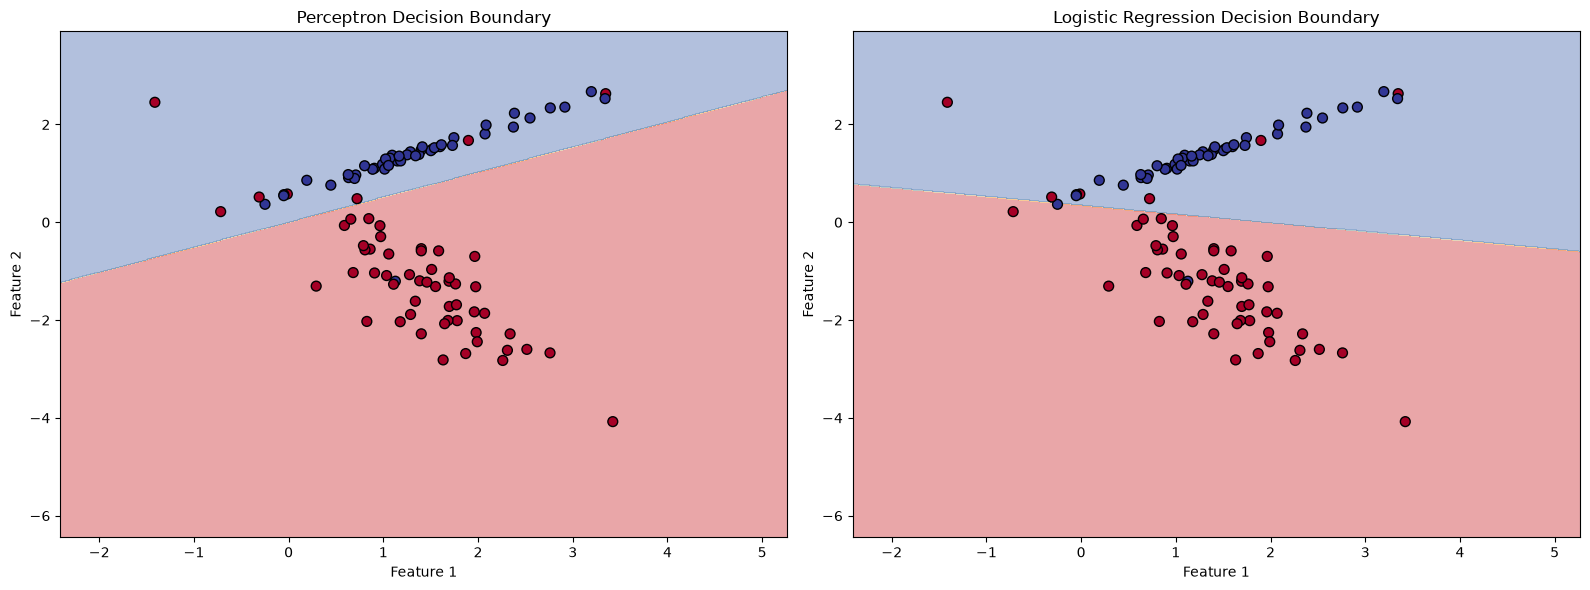


💡 Insight: Logistic regression is essentially a perceptron with a sigmoid activation
activation function, providing probabilistic outputs instead of hard classifications.


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Use the linearly separable dataset from Ex 2
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    flip_y=0.1,  # Add some noise
    random_state=42,
    class_sep=1.5
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train perceptron
perceptron = Perceptron(learning_rate=0.01, n_iterations=1000)
perceptron.fit(X_train, y_train)
y_pred_perceptron = perceptron.predict(X_test)

# Train logistic regression (perceptron with sigmoid activation)
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)

# Compare results
print("Performance Comparison:")
print("=" * 50)
print(f"\nPerceptron Accuracy: {accuracy_score(y_test, y_pred_perceptron) * 100:.2f}%")
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_logreg) * 100:.2f}%")

# Visualize both decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (model, title) in enumerate([(perceptron, 'Perceptron'), 
                                       (logreg, 'Logistic Regression')]):
    ax = axes[idx]
    
    # Create mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    
    # Predict
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot
    ax.contourf(xx, yy, Z, alpha=0.4, cmap='RdYlBu')
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdYlBu', 
               edgecolors='black', s=50)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title(f'{title} Decision Boundary')

plt.tight_layout()
plt.show()

print("\n💡 Insight: Logistic regression is essentially a perceptron with a sigmoid activation")
print("activation function, providing probabilistic outputs instead of hard classifications.")

> The probabilistic outputs could be interpreted as confidence for that class. Further from line, more confident and prob value for one class is higher. Closer to line, prob value for both classes are closer together. 

## Summary and Key Takeaways

### What We Learned:

1. **The Perceptron** is a simple binary classifier that forms the foundation of modern neural networks

2. **Linear Separability** is crucial - perceptrons can only solve linearly separable problems

3. **The XOR Problem** demonstrated the limitations of single-layer perceptrons and motivated multi-layer networks

4. **Modern Neural Networks** are multi-layer perceptrons with:
   - Multiple layers
   - Non-linear activation functions
   - Advanced optimization techniques

5. **Historical Impact**: Understanding the perceptron's history helps us appreciate how far deep learning has come

### Connection to Modern Deep Learning:

- Every neuron in a deep network is essentially a perceptron with a non-linear activation
- The fundamental operation (weighted sum + bias + activation) remains the same
- The perceptron learning algorithm inspired gradient descent and backpropagation
- Understanding perceptron limitations helps us understand why depth and non-linearity matter